# US Traffic Accidents Patterns and Severity Prediction


In [49]:
from pathlib import Path
import os, sys, json, subprocess, zipfile
IN_COLAB = 'google.colab' in sys.modules
if not IN_COLAB:
    try:
        import google.colab
        IN_COLAB = True
    except ImportError:
        pass
USE_DRIVE = False
if IN_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
ROOT = (Path('/content/drive/MyDrive/US_Traffic_Project') if USE_DRIVE else Path('/content/traffic_project')) if IN_COLAB else Path.cwd()
ROOT.mkdir(parents=True, exist_ok=True)
os.chdir(ROOT)
os.environ['MPLCONFIGDIR'] = str(ROOT / '.mpl_cache')
os.environ['LOKY_MAX_CPU_COUNT'] = '4'


In [50]:

archive = ROOT / 'project_code.zip'
if not (ROOT / 'src/pipeline.py').exists():
    if not archive.exists():
        from google.colab import files
        uploaded = files.upload()
        if 'project_code.zip' not in uploaded:
            raise FileNotFoundError('Выберите файл project_code.zip')
    with zipfile.ZipFile(archive) as bundle:
        for name in bundle.namelist():
            if not (ROOT / name).resolve().is_relative_to(ROOT.resolve()):
                raise ValueError('Недопустимый путь в ZIP')
        bundle.extractall(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))


In [51]:

if IN_COLAB:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', 'requirements.txt'], check=True)
import pandas as pd
from IPython.display import display, Image, HTML
from src.prepare import prepare_data
from src.download import download_dataset
from src.pipeline import run_analysis
from src.optimize import audit_and_optimize
from src.final_modeling import run
from src.menu import run_menu
import numpy as np
import matplotlib.pyplot as plt
PROCESSED = ROOT / 'data/processed'
PARQUET = PROCESSED / 'full_parquet'
OUT = ROOT / 'outputs'
OUT.mkdir(parents=True, exist_ok=True)
DATABASE = PROCESSED / 'accidents.db'


## Подготовленные данные и повторное использование


In [52]:
audit_path = PARQUET / 'audit.json'
if audit_path.exists():
    audit = json.loads(audit_path.read_text())
    if audit['rows'] != 7728394:
        raise ValueError('Ожидается полный набор 7 728 394 записи')
else:
    csv = download_dataset(ROOT / 'data/raw/US_Accidents_March23.csv')
    audit = prepare_data(csv, PARQUET)
import pyarrow.parquet as pq
assert sum(pq.ParquetFile(p).metadata.num_rows for p in PARQUET.glob('year=*/part-*.parquet')) == audit['rows']
print('Строк:', audit['rows'])


Строк: 7728394


## Аудит качества и числовой downcast


In [53]:
optimization = audit_and_optimize(PARQUET, PROCESSED / 'optimized_parquet', OUT / 'optimization_audit.json')
display(pd.Series(optimization['checks']).to_frame('Количество'))
display(pd.Series({k:optimization[k] for k in ['memory_before_bytes','numeric64_memory_bytes','memory_after_bytes','source_parquet_bytes','optimized_parquet_bytes']}).to_frame('Байт'))
print('Максимальные погрешности:', optimization['max_abs_rounding_error'])


,Количество
duplicate_id_extra_rows,0
candidate_event_duplicate_extra_rows,134471
missing_or_invalid_start,0
missing_or_invalid_end,0
end_before_start,0
start_outside_2016_2023,0
weather_after_start,3787674
weather_older_than_3h,17594
invalid_or_missing_severity,0
invalid_Start_Lat,0


,Байт
memory_before_bytes,20212502500
numeric64_memory_bytes,15502744615
memory_after_bytes,5827551641
source_parquet_bytes,831133788
optimized_parquet_bytes,815809088


Максимальные погрешности: {'Start_Lat': 0, 'Start_Lng': 0, 'End_Lat': 0, 'End_Lng': 0, 'Distance(mi)': 7.080078120225153e-06, 'Temperature(F)': 6.103515630684342e-06, 'Wind_Chill(F)': 1.5258789076710855e-06, 'Humidity(%)': 0, 'Pressure(in)': 1.6784667948854803e-06, 'Visibility(mi)': 1.9073486345888568e-07, 'Wind_Speed(mph)': 2.4414062522737368e-05, 'Precipitation(in)': 1.2207031261368684e-06}


## SQLite и агрегаты
Схема: `states(state_id PK, state_code UNIQUE)` связана 1:N с `accidents(accident_id PK, state_id FK, severity, start_time, weather)`. Таблица `project_info` хранит число загруженных строк. Код `src/database.py` содержит восемь SQL-запросов: JOIN, GROUP BY, HAVING, CTE, подзапрос и RANK OVER. Результаты загружаем в Pandas и сохраняем в CSV. Агрегаты сохраняем в SQLite и Parquet.

## Восемь SQL-запросов

В модуле src/database.py находятся все запросы. Функция `run_queries` выполняет каждый запрос, переводит его результат в Pandas DataFrame и сохраняет таблицу в CSV.

1. **Severity:** сколько записей относится к каждому уровню.
2. **JOIN:** соединяем ДТП со справочником штатов и выбираем 10 штатов с наибольшим числом записей.
3. **GROUP BY / HAVING:** группируем по штатам и оставляем только штаты с 10 000 или более записей. Среднее Severity здесь лишь описательный показатель для порядковой шкалы.
4. **Часы:** считаем количество ДТП по часу начала.
5. **Погода:** показываем 10 самых частых непустых значений.
6. **CTE и подзапрос:** сравниваем число записей штата со средним числом записей по штатам.
7. **Оконная функция RANK:** присваиваем штатам места по числу записей; при равенстве значений места совпадают.
8. **Годы и Severity:** считаем записи для каждой комбинации года и уровня.

Количество записей отражает доступные данные, а не риск ДТП. При небольшом демонстрационном наборе запрос №3 может вернуть пустую таблицу — это нормально.

In [54]:
results = run_analysis(PARQUET, DATABASE, OUT)
from src.database import QUERIES
for name, query in QUERIES.items():
    print(name, query.strip())
    display(pd.read_csv(OUT / 'sql' / (name + '.csv')).head(10))


Агрегаты сохранены в SQLite и Parquet.
Влияние ДТП на движение по уровням Severity: максимум в категории 2 — 6,156,981 записей.
ДТП по местному часу начала: максимум в категории 07 — 587,472 записей.
ДТП по году начала: максимум в категории 2022 — 1,762,452 записей.
Десять штатов с наибольшим числом записей: максимум в категории CA — 1,741,433 записей.
Количество записей по годам отражает также изменение покрытия источников; 2023 год неполный.
Число ДТП по штатам не является риском: нет знаменателя по пробегу, населению и интенсивности движения.
Пропуски конечных координат и Wind_Chill не заполняем для EDA; эти поля не нужны итоговой модели.
1_severity SELECT severity, COUNT(*) AS accidents
        FROM accidents GROUP BY severity ORDER BY severity


,severity,accidents
0,1,67366
1,2,6156981
2,3,1299337
3,4,204710


2_states_join SELECT s.state_code, COUNT(*) AS accidents
        FROM accidents a JOIN states s ON a.state_id = s.state_id
        GROUP BY s.state_code ORDER BY accidents DESC LIMIT 10


,state_code,accidents
0,CA,1741433
1,FL,880192
2,TX,582837
3,SC,382557
4,NY,347960
5,NC,338199
6,VA,303301
7,PA,296620
8,MN,192084
9,OR,179660


3_states_having SELECT s.state_code, COUNT(*) AS accidents,
               ROUND(AVG(a.severity), 2) AS average_severity
        FROM accidents a JOIN states s ON a.state_id = s.state_id
        GROUP BY s.state_code HAVING COUNT(*) >= 10000
        ORDER BY average_severity DESC


,state_code,accidents,average_severity
0,GA,169234,2.51
1,WI,34688,2.47
2,RI,16971,2.46
3,KY,32254,2.45
4,CO,90885,2.44
5,IA,26307,2.42
6,IN,67224,2.40
7,MO,77323,2.40
8,IL,168958,2.38
9,NM,10325,2.37


... (6 outputs left out)

7_state_rank WITH state_counts AS (
            SELECT s.state_code, COUNT(*) AS accidents
            FROM accidents a JOIN states s ON a.state_id = s.state_id
            GROUP BY s.state_code
        )
        SELECT state_code, accidents,
               RANK() OVER (ORDER BY accidents DESC) AS state_rank
        FROM state_counts ORDER BY state_rank


,state_code,accidents,state_rank
0,CA,1741433,1
1,FL,880192,2
2,TX,582837,3
3,SC,382557,4
4,NY,347960,5
5,NC,338199,6
6,VA,303301,7
7,PA,296620,8
8,MN,192084,9
9,OR,179660,10


8_year_severity SELECT SUBSTR(start_time, 1, 4) AS year, severity, COUNT(*) AS accidents
        FROM accidents WHERE start_time IS NOT NULL
        GROUP BY year, severity ORDER BY year, severity


,year,severity,accidents
0,2016,1,225
1,2016,2,270026
2,2016,3,126215
3,2016,4,14355
4,2017,1,282
5,2017,2,462474
6,2017,3,231169
7,2017,4,24168
8,2018,1,259
9,2018,2,574668


## EDA и интерпретация


### Числовые признаки: полный набор

,feature,count,mean,std,min,q25,median,q75,max,missing_percent,IQR
0,Start_Lat,7728394,36.201,5.076,24.555,33.400,35.824,40.085,49.002,0.000,6.685
1,Start_Lng,7728394,-94.703,17.392,-124.624,-117.219,-87.767,-80.354,-67.113,0.000,36.866
2,End_Lat,4325632,36.262,5.273,24.566,33.462,36.183,40.179,49.075,44.029,6.717
3,End_Lng,4325632,-95.726,18.108,-124.546,-117.754,-88.028,-80.247,-67.109,44.029,37.507
4,Distance(mi),7728394,0.562,1.777,0.000,0.000,0.030,0.464,441.750,0.000,0.464
5,Temperature(F),7564541,61.663,19.014,-89.000,49.000,64.000,76.000,207.000,2.120,27.000
6,Wind_Chill(F),5729375,58.251,22.390,-89.000,43.000,62.000,75.000,207.000,25.866,32.000
7,Humidity(%),7554250,64.831,22.821,1.000,48.000,67.000,84.000,100.000,2.253,36.000
8,Pressure(in),7587715,29.539,1.006,0.000,29.370,29.860,30.030,58.630,1.820,0.660
9,Visibility(mi),7551296,9.090,2.688,0.000,10.000,10.000,10.000,140.000,2.292,0.000


### describe() на выборке

,count,mean,std,min,1%,25%,50%,75%,99%,max
Temperature(F),40702.0,61.649,18.526,-27.9,14.0,50.0,63.0,75.2,96.0,113.0
Humidity(%),40653.0,65.593,22.697,2.0,12.0,49.0,68.0,85.0,100.0,100.0
Visibility(mi),40619.0,9.124,2.805,0.0,0.5,10.0,10.0,10.0,10.0,80.0
Wind_Speed(mph),36930.0,7.924,5.136,0.0,0.0,4.6,7.0,10.4,23.0,157.0
Pressure(in),40833.0,29.697,0.861,0.3,25.31,29.64,29.93,30.08,30.49,31.03
Precipitation(in),21017.0,0.013,0.149,0.0,0.0,0.0,0.0,0.0,0.23,10.02
Distance(mi),41611.0,0.326,1.557,0.0,0.0,0.0,0.0,0.066,5.42,78.671


### Выбросы по правилу 1,5 × IQR

,IQR,lower,upper,outside_count,observed_count,outside_percent
Temperature(F),25.2,12.2,113.0,338,40702,0.83
Humidity(%),36.0,-5.0,139.0,0,40653,0.0
Visibility(mi),0.0,10.0,10.0,8275,40619,20.372
Wind_Speed(mph),5.8,-4.1,19.1,1094,36930,2.962
Pressure(in),0.44,28.98,30.74,3669,40833,8.985
Precipitation(in),0.0,0.0,0.0,2893,21017,13.765
Distance(mi),0.066,-0.1,0.166,8966,41611,21.547


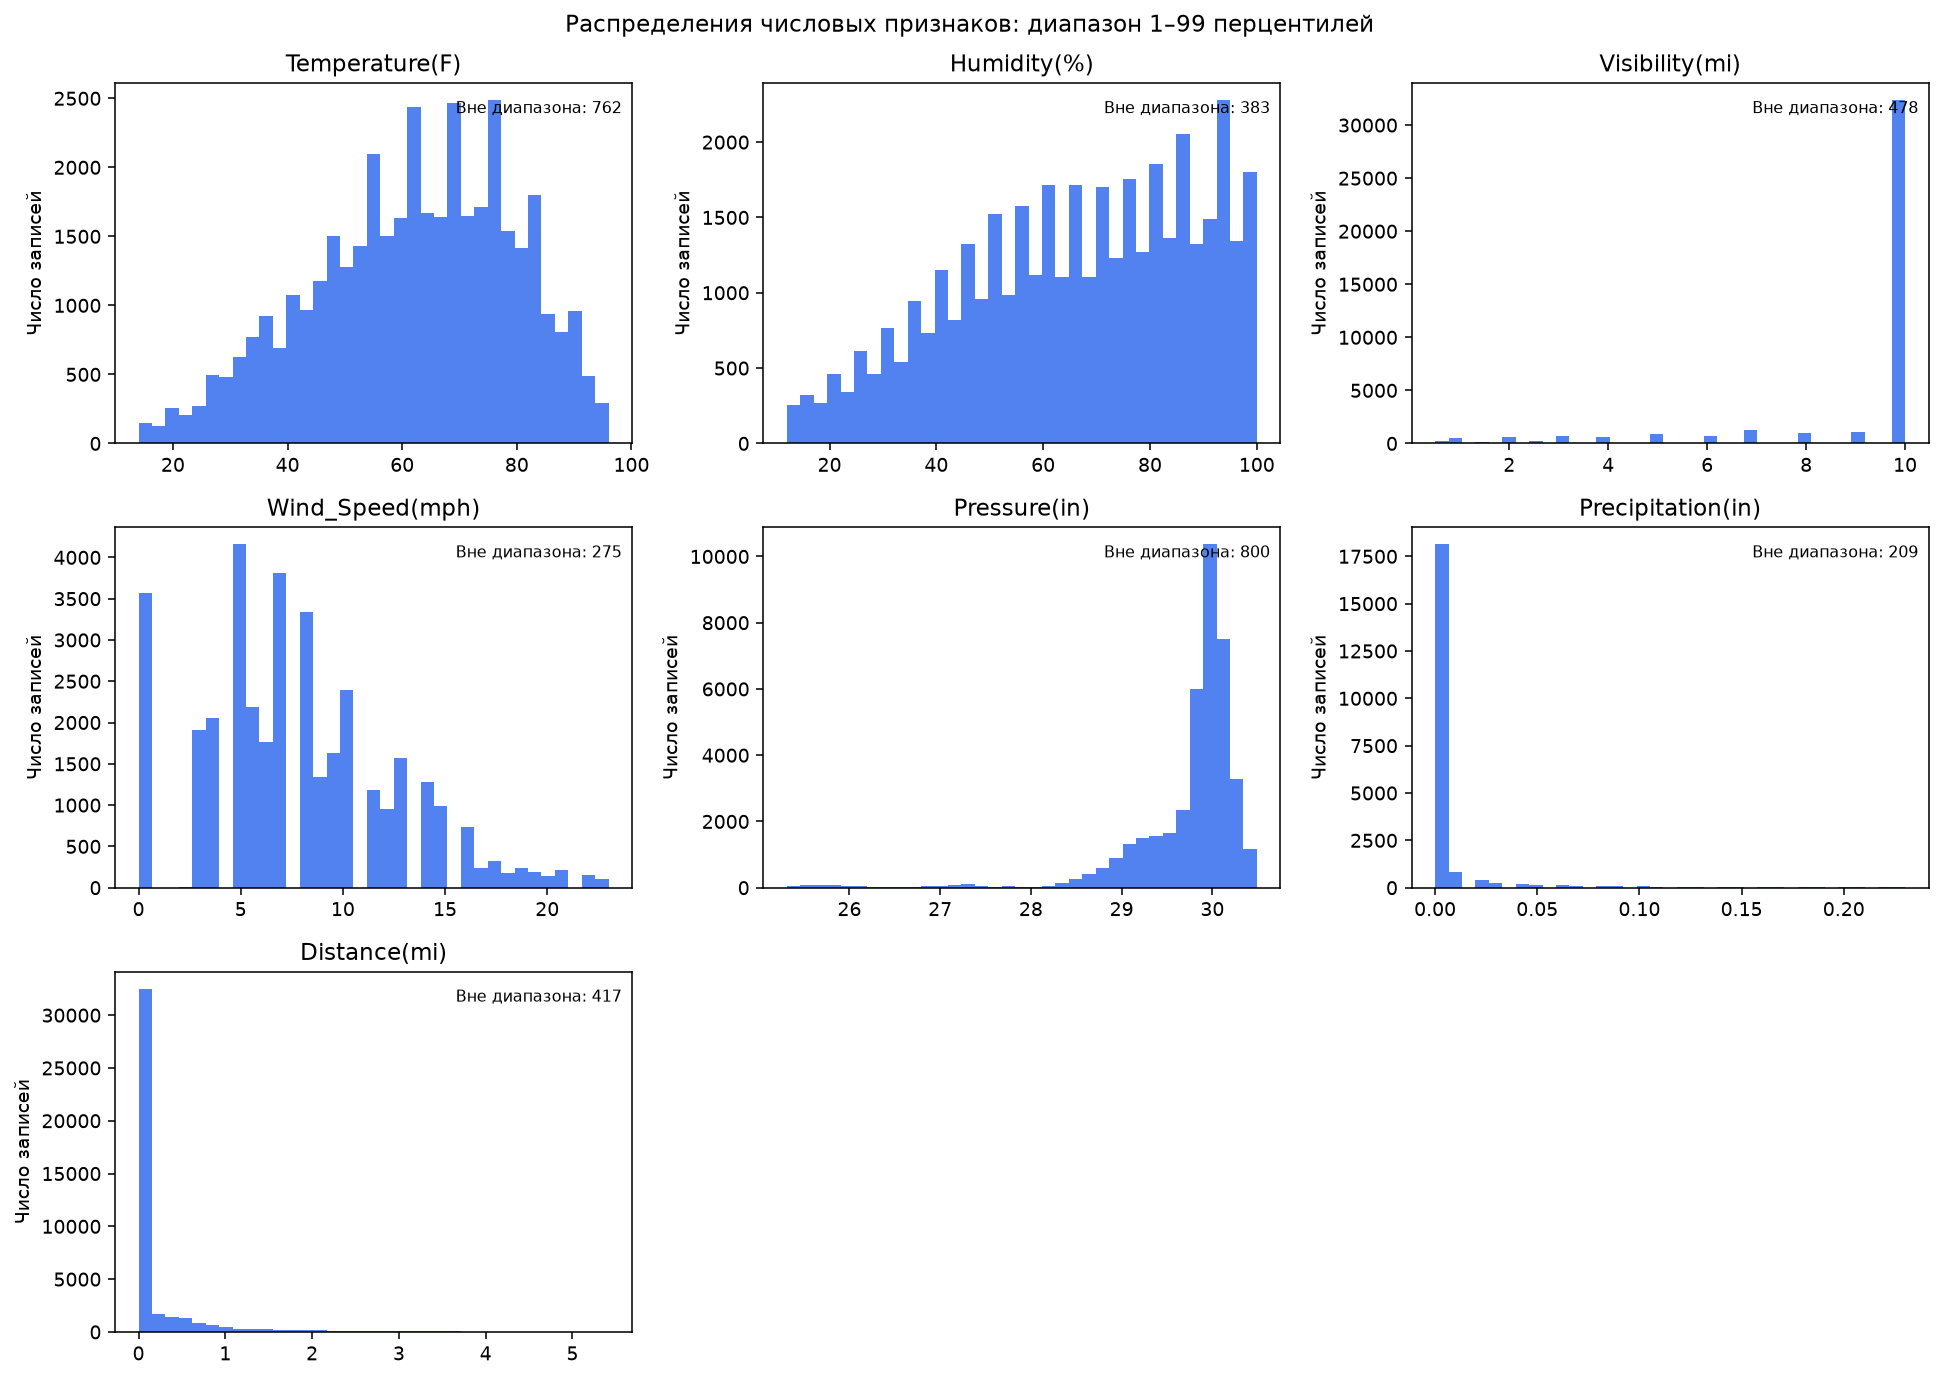

### Связи между числовыми признаками

,Temperature(F),Humidity(%),Visibility(mi),Wind_Speed(mph),Pressure(in),Precipitation(in),Distance(mi)
Temperature(F),40702,40653,40461,36803,40646,20899,40702
Humidity(%),40653,40653,40414,36758,40597,20869,40653
Visibility(mi),40461,40414,40619,36793,40560,20894,40619
Wind_Speed(mph),36803,36758,36793,36930,36886,20547,36930
Pressure(in),40646,40597,40560,36886,40833,20989,40833
Precipitation(in),20899,20869,20894,20547,20989,21017,21017
Distance(mi),40702,40653,40619,36930,40833,21017,41611


### Числовые признаки по Severity

Temperature(F)               Humidity(%)                \
                  count median   mean       count median   mean   
Severity                                                          
1                   303   72.0   70.4         303   54.0  52.34   
2                 28748   63.0  61.51       28709   68.0  65.59   
3                 10490   64.0  62.11       10481   68.0  65.71   
4                  1161   61.0  58.68        1160   72.0  68.01   

         Visibility(mi)              Wind_Speed(mph)  ...       Pressure(in)  \
                  count median  mean           count  ...  mean        count   
Severity                                              ...                      
1                   303   10.0  9.72             301  ...  7.98          304   
2                 28716   10.0  9.12           26300  ...  7.72        28853   
3                 10440   10.0  9.11            9295  ...  8.47        10514   
4                  1160   10.0   9.2            1034  ...  8.11         1162   

                       Precipitation(in)              Distance(mi)         \
         median   mean             count median  mean        count median   
Severity                                                                    
1         29.74   29.2               272    0.0   0.0          306    0.0   
2         29.92  29.68             15670    0.0  0.01        29379    0.0   
3         29.95  29.75              4484    0.0  0.02        10724    0.0   
4         29.94  29.68               591    0.0  0.02         1202   0.58   

                
          mean  
Severity        
1         0.21  
2         0.24  
3          0.4  
4          1.7  

[4 rows x 21 columns]

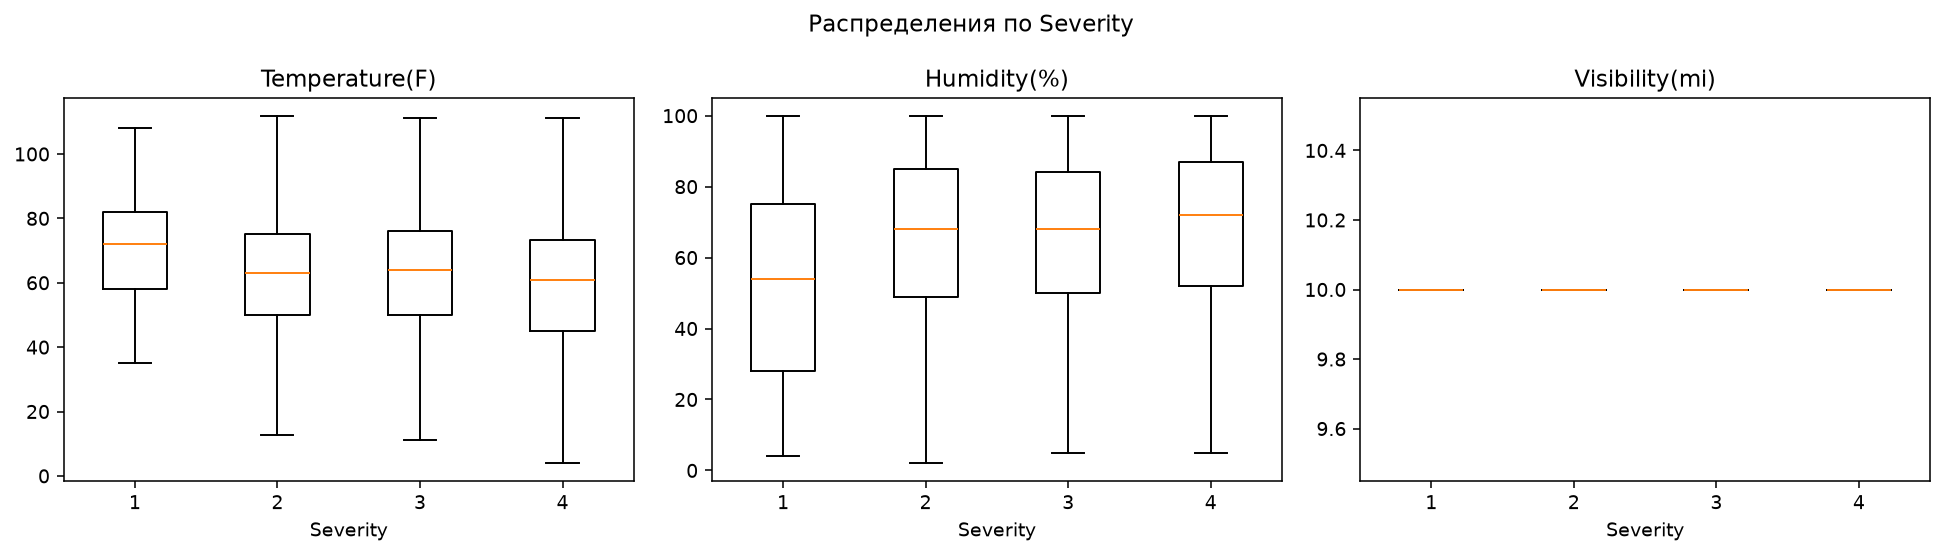

In [55]:
from src.numeric_eda import run_numeric_eda, show_plot

run_numeric_eda(PARQUET, OUT, total_rows=audit["rows"])

### Распределение Severity


In [56]:
import plotly.express as px

severity = results["severity"].sort_values("severity")
px.bar(severity, color_discrete_sequence=["#507dbc"], x="severity", y="accidents", title="Количество ДТП по уровню влияния на движение", labels={"severity": "Severity", "accidents": "Количество ДТП"}).show()

### Десять штатов


In [57]:
states = results["state"].head(10)
px.bar(states, color_discrete_sequence=["#2a9d8f"], x="state", y="accidents", title="10 штатов с наибольшим числом записей", labels={"state": "Штат", "accidents": "Количество ДТП"}).show()

### Местный час начала


In [58]:
hours = results["hour"].sort_values("hour")
px.bar(hours, color_discrete_sequence=["#e9a23b"], x="hour", y="accidents", title="Распределение ДТП по часу начала", labels={"hour": "Местный час", "accidents": "Количество ДТП"}).show()

### Количество записей по годам


In [59]:
years = results["year"].sort_values("year")
px.bar(years, color_discrete_sequence=["#8064a2"], x="year", y="accidents", title="Количество записей по годам", labels={"year": "Год", "accidents": "Количество ДТП"}).show()

### Частые погодные условия


In [60]:
weather = results["weather"].head(10)
px.bar(weather, color_discrete_sequence=["#d96c6c"], x="weather", y="accidents", title="10 наиболее частых погодных условий", labels={"weather": "Погодные условия", "accidents": "Количество ДТП"}).show()

### Пропуски в исходных данных



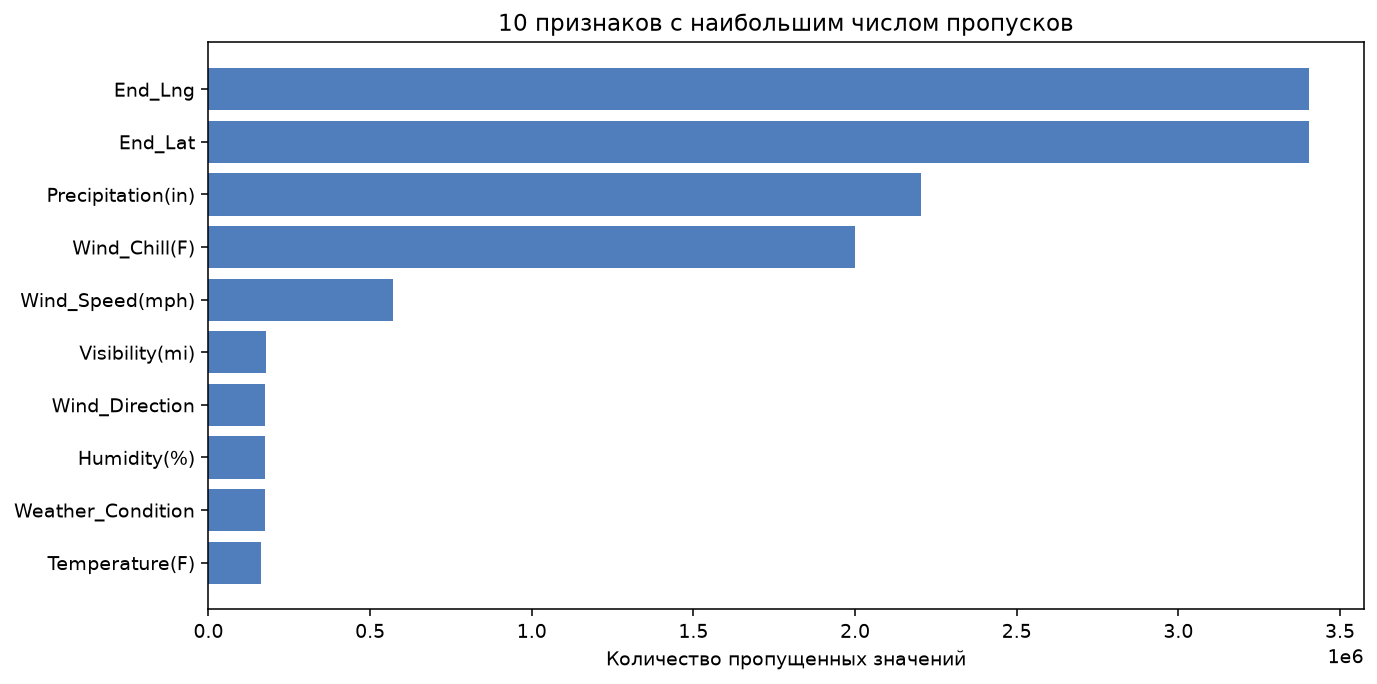

In [61]:
import matplotlib.pyplot as plt

missing = pd.DataFrame(list(audit["missing"].items()), columns=["Признак", "Пропуски"])
missing = missing.sort_values("Пропуски", ascending=False).head(10)
plt.figure(figsize=(10, 5))
plt.barh(missing["Признак"], missing["Пропуски"], color="#507dbc")
plt.gca().invert_yaxis()
plt.title("10 признаков с наибольшим числом пропусков")
plt.xlabel("Количество пропущенных значений")
plt.tight_layout()
show_plot()

## Две гипотезы и размер связи
H0: погода и Severity независимы. H0: день/ночь и Severity независимы. Используем chi-square и Cramer V.

In [62]:
quality_file = OUT / 'quality_hypotheses.json'
if not quality_file.exists():
    subprocess.run([sys.executable, '-m', 'src.pipeline', 'quality'], check=True)
hypotheses = json.loads(quality_file.read_text())
display(pd.DataFrame({k:v for k,v in hypotheses.items() if k != 'quality'}).T)


,observations,chi2,p_value,degrees_of_freedom,cramers_v,expected_below_5
weather_test,7554935.0,36600.615364,0.0,12.0,0.040185,0.0
day_test,7705148.0,19504.955913,0.0,3.0,0.050313,0.0


### Таблицы проверки гипотез


In [63]:
weather_table = pd.read_csv(OUT / 'weather_severity.csv', index_col=0)
day_table = pd.read_csv(OUT / 'day_severity.csv', index_col=0)
display(weather_table)
display(day_table)


,1,2,3,4
Clear / fair,35054,2794392,488494,87276
Cloudy,26065,2452646,601983,83056
Rain / storm,3824,437040,116562,14756
Snow / ice,125,133313,27881,6524
Other,1344,204809,34122,5669


,1,2,3,4
Day,54914,4227081,933168,119390
Night,12248,1909821,365480,83046


### Распределение Severity днём и ночью


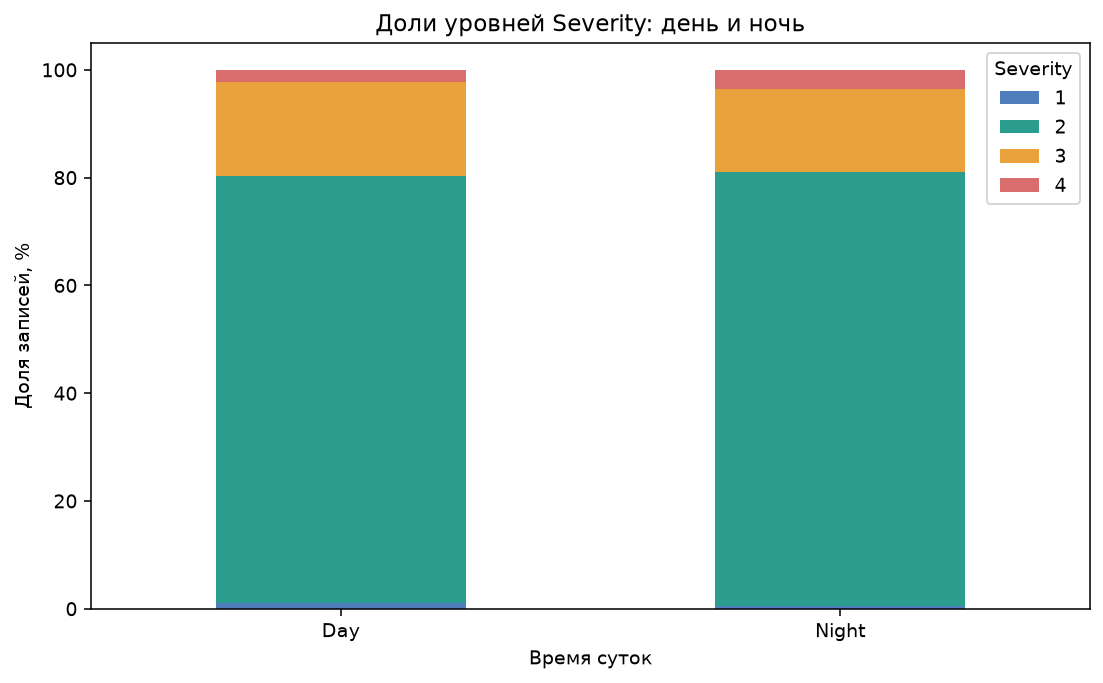

In [64]:
day_percent = day_table.div(day_table.sum(axis=1).replace(0, np.nan), axis=0) * 100
ax = day_percent.plot(kind="bar", stacked=True, figsize=(8, 5),
                      color=["#507dbc", "#2a9d8f", "#e9a23b", "#d96c6c"])
ax.set_title("Доли уровней Severity: день и ночь")
ax.set_xlabel("Время суток")
ax.set_ylabel("Доля записей, %")
ax.legend(title="Severity")
plt.xticks(rotation=0)
plt.tight_layout()
show_plot()

Сравниваем доли внутри дня и ночи. Различия описывают состав зарегистрированных ДТП, но не доказывают причинный эффект освещённости.

## Pandas против Polars


In [65]:
from src.benchmark import compare_tools
benchmark_file = OUT / 'pandas_polars_benchmark.csv'
if not benchmark_file.exists():
    table, counts = compare_tools(PARQUET)
    table.to_csv(benchmark_file,index=False)
display(pd.read_csv(benchmark_file))


,tool,seconds,peak_memory_mb,run
0,Pandas,3.201656,173.984375,1
1,Polars,0.738001,89.066406,1
2,Polars,0.535897,87.093750,2
3,Pandas,2.649934,165.390625,2


## Финальный протокол моделей
Train: до 2021 года, старые 30% по хешу ID. Validation: 2021, те же 30%. Test: 2022–2023, другие 10% по хешу [3000,4000), вне прежних модельных экспериментов. Полный набор уже использован в EDA, поэтому абсолютную независимость не заявляем. Подробности в `docs/FINAL_PROTOCOL.md`.

Baseline Dummy обучается на естественных долях. Logistic и HGB используют одинаковые уникальные train-строки, до 50 000 каждого класса без повторов. Варианты весов HGB сравниваются только по validation natural F1-macro. После фиксации победителя test оценивается один раз. Сохранённые результаты используются повторно.


In [66]:
import importlib
import src.final_modeling as modeling

for name in [
    "OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS",
    "MKL_NUM_THREADS", "BLIS_NUM_THREADS",
    "NUMEXPR_NUM_THREADS", "VECLIB_MAXIMUM_THREADS",
]:
    os.environ[name] = "1"

os.environ["TRAFFIC_NUM_THREADS"] = "1"
os.environ["PYTHONFAULTHANDLER"] = "1"

module_path = Path(modeling.__file__)
source = module_path.read_text(encoding="utf-8")
source = source.replace(
    "threadpool_limits(limits=4)",
    "threadpool_limits(limits=1)",
)
module_path.write_text(source, encoding="utf-8")
modeling = importlib.reload(modeling)

scores = modeling.run(PARQUET, OUT / "final")
display(pd.read_csv(OUT / "final/validation_scores.csv"))
print((OUT / "final/selection_before_test.json").read_text())
display(scores)

Финальная оценка уже выполнена. Используем сохранённые результаты.


,model,accuracy,f1_macro,train_seconds,validation_predict_seconds,peak_process_ram_mib,before_fit_ram_mib,train_rows,train_unique_ids
0,dummy,0.884580,0.234689,0.049942,0.042337,1153.402344,1019.281250,1247472,1247472
1,logistic,0.311501,0.184172,13.061027,1.059075,677.617188,564.156250,146091,146091
2,hgb_balanced,0.435658,0.239965,39.902920,56.393265,785.304688,563.921875,146091,146091
3,hgb_sqrt,0.462786,0.250583,39.000724,56.024730,785.234375,563.128906,146091,146091
4,hgb_none,0.490779,0.258172,39.660132,56.631516,785.488281,563.597656,146091,146091
5,hgb_none_no_weather,0.492163,0.259342,34.405502,51.328440,729.429688,564.027344,146091,146091


{
  "selected_model": "hgb_none",
  "selected_hgb": "hgb_none",
  "selection_metric": "validation natural F1-macro",
  "protocol": "docs/FINAL_PROTOCOL.md",
  "test_used_for_selection": false
}


,model,accuracy_natural,f1_macro_natural,accuracy_equal_classes,f1_macro_equal_classes,test_rows,equal_test_rows,predict_seconds
0,dummy,0.918391,0.239365,0.250000,0.100000,200432,15096,0.036939
1,logistic,0.223208,0.138265,0.342740,0.332305,200432,15096,0.433536
2,hgb_none,0.398419,0.208102,0.435281,0.390025,200432,15096,24.031352
3,hgb_none_no_weather,0.398494,0.208482,0.436473,0.390992,200432,15096,22.063080


## Метрики слабых классов и ошибки


In [67]:
selection = json.loads((OUT / 'final/selection_before_test.json').read_text())
selected = selection['selected_hgb']
display(pd.read_csv(OUT / f'final/{selected}_test_classes.csv',index_col=0))
display(pd.read_csv(OUT / f'final/{selected}_test_confusion.csv',index_col=0))
display(pd.read_csv(OUT / f'final/{selected}_test_weather_errors.csv'))


,precision,recall,f1-score,support
1,0.022787,0.034711,0.027512,3774.000000
2,0.942231,0.387570,0.549226,184075.000000
3,0.069513,0.701219,0.126488,7631.000000
4,0.072209,0.612278,0.129183,4952.000000
accuracy,0.398419,0.398419,0.398419,0.398419
macro avg,0.276685,0.433945,0.208102,200432.000000
weighted avg,0.870197,0.398419,0.512930,200432.000000


,1,2,3,4
1,131,2674,759,210
2,5388,71342,69872,37473
3,171,835,5351,1274
4,59,865,996,3032


,weather_group,n,accuracy,f1_macro,support_1,support_2,support_3,support_4
0,Clear / fair,48237,0.437838,0.227176,1041,44174,1804,1218
1,Cloudy,36347,0.368669,0.195329,754,33255,1491,847
2,Other,3228,0.447955,0.234833,58,2942,124,104
3,Rain / storm,7268,0.325812,0.174863,77,6722,297,172
4,Snow / ice,3253,0.333846,0.173849,1,3027,127,98
5,Unknown,102099,0.396047,0.205676,1843,93955,3788,2513


## Original Contribution / Additional Experiments
Одна HGB с погодой и без неё использует те же строки, настройки и веса. Сравниваем F1-macro, Accuracy и время. Дополнительно анализируем ошибки по погодным группам с n и support всех классов. Разница метрик не доказывает причинное влияние погоды.


In [68]:
display(scores[scores.model.str.startswith('hgb')])
validation_scores = pd.read_csv(OUT / 'final/validation_scores.csv')
display(validation_scores[validation_scores.model.isin([selected, selected + '_no_weather'])])


,model,accuracy_natural,f1_macro_natural,accuracy_equal_classes,f1_macro_equal_classes,test_rows,equal_test_rows,predict_seconds
2,hgb_none,0.398419,0.208102,0.435281,0.390025,200432,15096,24.031352
3,hgb_none_no_weather,0.398494,0.208482,0.436473,0.390992,200432,15096,22.063080


,model,accuracy,f1_macro,train_seconds,validation_predict_seconds,peak_process_ram_mib,before_fit_ram_mib,train_rows,train_unique_ids
4,hgb_none,0.490779,0.258172,39.660132,56.631516,785.488281,563.597656,146091,146091
5,hgb_none_no_weather,0.492163,0.259342,34.405502,51.328440,729.429688,564.027344,146091,146091


## Интерактивное меню


In [69]:
%%writefile streamlit_app.py
import os
import sqlite3
from pathlib import Path

import pandas as pd
import plotly.express as px
import streamlit as st

st.set_page_config(
    page_title="US Traffic Accidents",
    page_icon="🚦",
    layout="wide",
)

DATABASE = Path(os.environ["TRAFFIC_DATABASE"])

st.title("🚦 US Traffic Accidents")
st.caption("Анализ влияния ДТП на движение · 2016–2023")

if not DATABASE.is_file():
    st.error("Сначала выполните раздел создания SQLite в ноутбуке.")
    st.stop()


@st.cache_data(max_entries=2)
def load_data(database, year, modified):
    query = """
        SELECT
            s.state_code AS state,
            a.severity,
            SUBSTR(a.start_time, 12, 2) AS hour,
            COALESCE(a.weather, 'Unknown') AS weather,
            COUNT(*) AS accidents
        FROM accidents a
        JOIN states s ON a.state_id = s.state_id
        WHERE a.start_time >= ? AND a.start_time < ?
        GROUP BY s.state_code, a.severity,
                 SUBSTR(a.start_time, 12, 2), a.weather
    """
    uri = Path(database).resolve().as_uri() + "?mode=ro"
    with sqlite3.connect(uri, uri=True) as connection:
        return pd.read_sql_query(
            query,
            connection,
            params=[f"{year}-01-01", f"{year + 1}-01-01"],
        )


def summarize(data, column, classes):
    data = data.copy()
    data["selected"] = data.accidents.where(
        data.severity.isin(classes), 0
    )
    result = (
        data.groupby(column)[["accidents", "selected"]]
        .sum()
        .reset_index()
    )
    result["share"] = 100 * result.selected / result.accidents
    return result


with st.sidebar:
    st.header("Фильтры")
    year = st.selectbox("Год", list(range(2016, 2024)), index=4)

with st.spinner("Получаем агрегаты из SQLite…"):
    data = load_data(
        str(DATABASE), year, DATABASE.stat().st_mtime_ns
    )

if data.empty:
    st.warning("За выбранный год нет данных.")
    st.stop()

with st.sidebar:
    state = st.selectbox(
        "Штат", ["Все штаты"] + sorted(data.state.unique())
    )
    target = st.selectbox(
        "Сравниваем долю",
        ["Severity 3–4", "Severity 1", "Severity 2",
         "Severity 3", "Severity 4"],
    )
    minimum = st.number_input(
        "Минимум ДТП в сравниваемой группе",
        min_value=0, value=1000, step=100,
    )
    st.caption("Изменение фильтров автоматически обновляет анализ.")
    if year == 2023:
        st.warning("2023 год неполный.")

classes = [3, 4] if target == "Severity 3–4" else [int(target[-1])]
region = data if state == "Все штаты" else data[data.state == state]

count = int(region.accidents.sum())
selected_count = int(
    region.loc[region.severity.isin(classes), "accidents"].sum()
)
share = 100 * selected_count / count
national_share = (
    100
    * data.loc[data.severity.isin(classes), "accidents"].sum()
    / data.accidents.sum()
)

cards = st.columns(4)
cards[0].metric("Все зарегистрированные ДТП", f"{count:,}")
cards[1].metric(target, f"{selected_count:,}")
cards[2].metric("Доля выбранных классов", f"{share:.2f}%")
cards[3].metric(
    "Разница со всеми штатами",
    f"{share - national_share:+.2f} п.п.",
)

st.caption(
    f"Общий уровень за {year}: {national_share:.2f}%. "
    "Он включает выбранный штат. Доля считается среди всех "
    "зарегистрированных ДТП выбранной группы."
)

section = st.radio(
    "Что сравнить?", ["По часам", "По погоде", "По штатам"],
    horizontal=True,
)
dimension = {
    "По часам": "hour",
    "По погоде": "weather",
    "По штатам": "state",
}[section]

base = data if dimension == "state" else region
table = summarize(base, dimension, classes)
reference = summarize(data, dimension, classes)[
    [dimension, "share"]
].rename(columns={"share": "reference"})

table = table.merge(reference, on=dimension)
if dimension == "state":
    table["reference"] = national_share
    st.info(
        "Сейчас сравниваются все штаты. Выбранный штат "
        "выделяется синим на графике."
    )

table["difference"] = table.share - table.reference
hidden = int((table.accidents < minimum).sum())
table = table[table.accidents >= minimum].copy()

if table.empty:
    st.warning("Нет групп с таким числом ДТП. Уменьшите порог слева.")
    st.stop()

order = st.selectbox(
    "Сортировка",
    ["Название / час", "Доля класса", "Разница", "Количество ДТП"],
)
sort_column = {
    "Название / час": dimension,
    "Доля класса": "share",
    "Разница": "difference",
    "Количество ДТП": "accidents",
}[order]
table = table.sort_values(
    sort_column, ascending=sort_column == dimension
)

best = table.loc[table.share.idxmax()]
st.subheader("Что видно в выбранных данных")
st.write(
    f"Среди групп с ≥ {minimum:,} ДТП наибольшая доля "
    f"**{target}** у **{best[dimension]}**: "
    f"**{best.share:.2f}%** "
    f"({int(best.selected):,} из {int(best.accidents):,}). "
    f"Отличие от уровня сравнения: "
    f"**{best.difference:+.2f} процентного пункта**."
)
st.caption(
    f"Скрыто малых групп: {hidden}. "
    "Это описательное сравнение, а не доказательство причинности."
)

chart_tab, table_tab = st.tabs(
    ["Сравнение", "Таблица и скачивание"]
)

with chart_tab:
    plot = table.head(24).copy()
    plot[dimension] = plot[dimension].astype(str)
    plot["highlight"] = plot[dimension].apply(
        lambda value: "Выбранный штат"
        if dimension == "state" and value == state else "Группа"
    )

    figure = px.bar(
        plot,
        x=dimension,
        y="share",
        color="highlight",
        color_discrete_map={
            "Группа": "#14b8a6",
            "Выбранный штат": "#2563eb",
        },
        hover_data=["accidents", "selected", "difference"],
        labels={
            dimension: section,
            "share": "Доля, %",
            "accidents": "Все ДТП",
            "selected": "Выбранные классы",
            "difference": "Разница, п.п.",
            "highlight": "",
        },
    )
    figure.add_scatter(
        x=plot[dimension],
        y=plot.reference,
        mode="markers",
        marker={"color": "#0f172a", "symbol": "diamond", "size": 9},
        name="Уровень сравнения по всем штатам",
    )
    figure.update_layout(
        template="plotly_white",
        height=460,
        legend={"orientation": "h", "y": 1.15},
    )
    figure.update_xaxes(type="category")
    st.plotly_chart(figure, use_container_width=True)

    if len(table) > 24:
        st.caption(
            "На графике первые 24 группы согласно сортировке. "
            "Полный список доступен в таблице и CSV."
        )

with table_tab:
    readable = table.rename(columns={
        dimension: "Группа",
        "accidents": "Все ДТП",
        "selected": "Выбранные классы",
        "share": "Доля, %",
        "reference": "Уровень сравнения, %",
        "difference": "Разница, п.п.",
    })
    st.dataframe(
        readable.round(2), hide_index=True, use_container_width=True
    )
    exported = readable.assign(
        year=year,
        region=state,
        target=target,
        minimum_count=minimum,
    )
    st.download_button(
        "Скачать сравнение CSV",
        data=exported.to_csv(index=False).encode("utf-8-sig"),
        file_name=f"accidents_{year}_{dimension}.csv",
        mime="text/csv",
    )


Overwriting streamlit_app.py


In [70]:

import os
import sys
import time
import subprocess
from pathlib import Path
from urllib.request import urlopen
from urllib.error import URLError
from google.colab import output

if not Path(DATABASE).is_file():
    raise FileNotFoundError(
        "SQLite не найдена. Сначала выполните раздел создания базы."
    )

app_path = Path("streamlit_app.py").resolve()
if not app_path.is_file():
    raise FileNotFoundError("Сначала выполните ячейку выше.")

subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "streamlit==1.45.1"],
    check=True,
)

# При повторном запуске останавливаем только ранее запущенную нами панель.
previous = globals().get("_dashboard_process")
if previous is not None and previous.poll() is None:
    previous.terminate()
    try:
        previous.wait(timeout=5)
    except subprocess.TimeoutExpired:
        previous.kill()
        previous.wait()

environment = os.environ.copy()
environment["TRAFFIC_DATABASE"] = str(Path(DATABASE).resolve())
log_path = Path(OUT) / "streamlit.log"

with log_path.open("w") as log:
    _dashboard_process = subprocess.Popen(
        [
            sys.executable, "-m", "streamlit", "run", str(app_path),
            "--server.port", "8501",
            "--server.address", "127.0.0.1",
            "--server.headless", "true",
            "--browser.gatherUsageStats", "false",
            "--server.enableWebsocketCompression", "false",
            "--server.enableCORS", "false",
            "--server.enableXsrfProtection", "false",
        ],
        env=environment,
        stdout=log,
        stderr=subprocess.STDOUT,
    )

for attempt in range(60):
    if _dashboard_process.poll() is not None:
        raise RuntimeError(log_path.read_text()[-3000:])
    try:
        with urlopen(
            "http://127.0.0.1:8501/_stcore/health", timeout=1
        ) as response:
            if response.status == 200:
                break
    except (URLError, OSError):
        time.sleep(0.5)
else:
    raise TimeoutError(
        "Сервер не ответил. Подробности в outputs/streamlit.log."
    )

print("Streamlit запущен. Интерфейс появится ниже.")
output.serve_kernel_port_as_iframe(8501, height=1100)

Streamlit запущен. Интерфейс появится ниже.


<IPython.core.display.Javascript object>

## Сохранение

In [71]:
import shutil
archive = shutil.make_archive(str(ROOT / 'traffic_results'), 'zip', OUT)
if IN_COLAB:
    from google.colab import files
    files.download(archive)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>